In [84]:
#load library
import pandas as pd
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [85]:
#load data set
df=pd.read_csv("C:\\Users\\Roshni\\Downloads\\retail_large_dataset.csv")

In [86]:
#understanding the data set
#inspectig the data set
#dimension, columns,

In [87]:
df.shape

(100000, 18)

In [88]:
df.columns

Index(['customer_id', 'age', 'gender', 'city', 'state', 'customer_segment',
       'order_id', 'order_date', 'product_category', 'product_subcategory',
       'product_price', 'quantity', 'discount_percentage', 'final_price',
       'payment_method', 'shipping_type', 'delivery_days', 'return_status'],
      dtype='object')

In [89]:
#first five rows
df.head()

,customer_id,age,gender,city,state,customer_segment,order_id,order_date,product_category,product_subcategory,product_price,quantity,discount_percentage,final_price,payment_method,shipping_type,delivery_days,return_status
0,C10000,56,Male,Hyderabad,Telangana,New,O50000,2025-05-10,Health,Protein Powder,38658,3,7,107855.82,Debit Card,Standard,5,No
1,C10001,36,Male,Pune,Maharashtra,Premium,O50001,2023-11-27,Electronics,Smartphone,22462,4,20,71878.40,Cash on Delivery,Standard,4,Yes
2,C10002,20,Male,Kolkata,West Bengal,New,O50002,2025-02-08,Fashion,Women Dress,56601,2,27,82637.46,Credit Card,Standard,5,No
3,C10003,39,Female,Jaipur,Rajasthan,New,O50003,2024-04-19,Beauty,Perfume,26158,3,9,71411.34,UPI,Standard,3,No
4,C10004,20,Male,Chennai,Tamil Nadu,Premium,O50004,2024-10-08,Beauty,Shampoo,31240,1,6,29365.60,UPI,Standard,2,No


In [90]:
df.drop("customer_id",axis=1,inplace=True)

In [91]:
df.head()

,age,gender,city,state,customer_segment,order_id,order_date,product_category,product_subcategory,product_price,quantity,discount_percentage,final_price,payment_method,shipping_type,delivery_days,return_status
0,56,Male,Hyderabad,Telangana,New,O50000,2025-05-10,Health,Protein Powder,38658,3,7,107855.82,Debit Card,Standard,5,No
1,36,Male,Pune,Maharashtra,Premium,O50001,2023-11-27,Electronics,Smartphone,22462,4,20,71878.40,Cash on Delivery,Standard,4,Yes
2,20,Male,Kolkata,West Bengal,New,O50002,2025-02-08,Fashion,Women Dress,56601,2,27,82637.46,Credit Card,Standard,5,No
3,39,Female,Jaipur,Rajasthan,New,O50003,2024-04-19,Beauty,Perfume,26158,3,9,71411.34,UPI,Standard,3,No
4,20,Male,Chennai,Tamil Nadu,Premium,O50004,2024-10-08,Beauty,Shampoo,31240,1,6,29365.60,UPI,Standard,2,No


In [92]:
#missing values
df.isna().sum()

age                    0
gender                 0
city                   0
state                  0
customer_segment       0
order_id               0
order_date             0
product_category       0
product_subcategory    0
product_price          0
quantity               0
discount_percentage    0
final_price            0
payment_method         0
shipping_type          0
delivery_days          0
return_status          0
dtype: int64

In [93]:
#cont dependent  variable vs cont independent variable

In [94]:
ContVar=df.columns[df.dtypes!="object"]

In [95]:
ContVar

Index(['age', 'product_price', 'quantity', 'discount_percentage',
       'final_price', 'delivery_days'],
      dtype='object')

<Axes: >

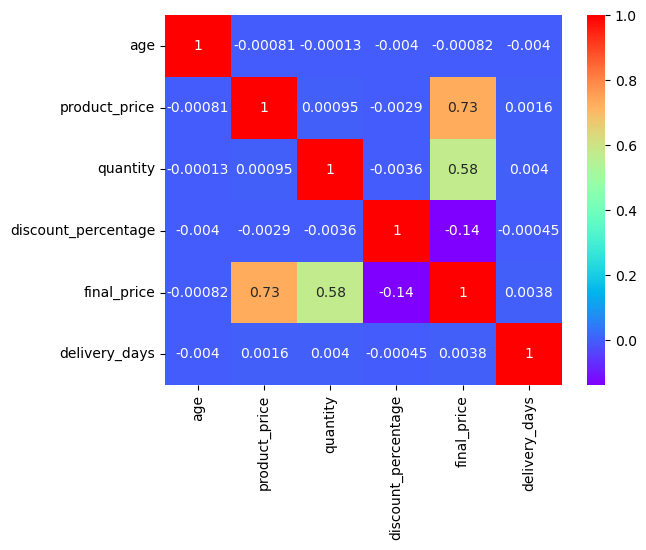

In [96]:
sns.heatmap(df[ContVar].corr(),annot=True,cmap="rainbow")

<Axes: xlabel='city', ylabel='age'>

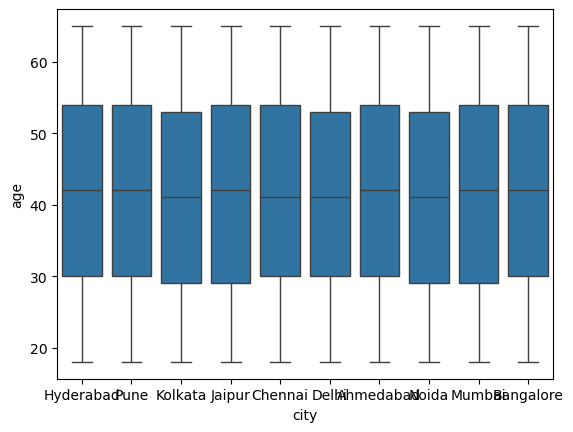

In [97]:
sns.boxplot(x=df["city"],y=df["age"])

<Axes: xlabel='gender', ylabel='final_price'>

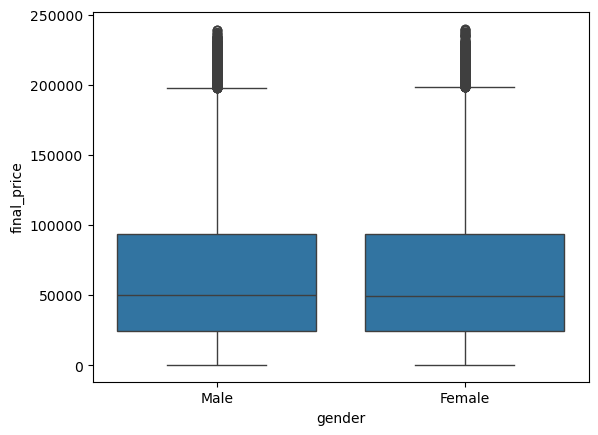

In [98]:
sns.boxplot(x=df["gender"],y=df["final_price"])

In [99]:
#This will show how the purchase value (final_price) varies across genders.

###IQR Method

In [100]:
Q1=df['product_price'].quantile(0.25)

In [101]:
Q3=df['product_price'].quantile(0.75)

In [102]:
IQR=Q3-Q1

In [103]:
lower_bound=Q1-1.5*IQR

In [104]:
upper_bound=Q3+1.5*IQR

In [105]:
outliers=df[(df['product_price']<lower_bound)|(df['product_price']>upper_bound)]
print("Number of ouliers:", len(outliers))

Number of ouliers: 0


In [106]:
columns=['age', 'quantity', 'discount_percentage', 'delivery_days']
for column in columns:
    Q1=df[column].quantile(0.25)
    Q3=df[column].quantile(0.75)

    IQR=Q3-Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
    (df[column]<lower_bound)|
    (df[column]>upper_bound)
        ]
    print(column,":", len(outliers), "outliers")

age : 0 outliers
quantity : 0 outliers
discount_percentage : 0 outliers
delivery_days : 0 outliers


In [107]:
#So according to IQR analysis, all the numerical columns you tested have 0 outliers

In [108]:
#Z-Score Method

In [109]:
from scipy.stats import zscore

In [110]:
numerical_columns = ['age', 'product_price', 'quantity', 'discount_percentage','final_price', 'delivery_days']
for column in numerical_columns:
    z_score = zscore(df[column])
    outliers = df[abs(z_score)> 3 ]
    print(column,":",len(outliers), "outliers")

age : 0 outliers
product_price : 0 outliers
quantity : 0 outliers
discount_percentage : 0 outliers
final_price : 503 outliers
delivery_days : 0 outliers


In [111]:
#According to the Z-score method, final_price has 503 potential outliers, while the other numerical variables have none.

#This is interesting because IQR method detected 0 outliers for final_price, but the Z-score method detected 503.

#data specifically states that outliers may represent valid high-value transactions and should be interpreted rather than automatically removed.

In [112]:
#inspect those 503 outliers

In [113]:
final_price_zscore = zscore(df['final_price'])

final_price_outliers = df[abs(final_price_zscore) > 3]

final_price_outliers[['product_price', 'quantity', 'discount_percentage', 'final_price']].head(10)

,product_price,quantity,discount_percentage,final_price
250,54561,4,0,218244.00
375,59542,4,1,235786.32
646,57190,4,3,221897.20
1170,56248,4,0,224992.00
1253,57604,4,6,216591.04
1298,57812,4,4,221998.08
1332,58826,4,2,230597.92
1449,56900,4,5,216220.00
1728,57193,4,2,224196.56
2252,58686,4,8,215964.48


In [114]:
#Z-score analysis identified 503 potential outliers in the final_price variable. Examination of these observations showed that they were associated with high product prices and larger purchase quantities, resulting in genuinely high-value transactions. Therefore, these observations were retained for further analysis rather than being removed.

In [115]:
len(final_price_outliers)

503

In [116]:
(len(final_price_outliers)/len(df)) * 100

0.503

In [117]:
final_price_outliers['final_price'].describe()

count       503.000000
mean     222939.080000
std        6177.358756
min      214094.520000
25%      217678.720000
50%      222001.960000
75%      226960.080000
max      239980.000000
Name: final_price, dtype: float64

In [118]:
df['final_price'].describe()

count    100000.000000
mean      64165.723382
std       49969.280150
min         357.000000
25%       24705.000000
50%       49752.390000
75%       94046.070000
max      239980.000000
Name: final_price, dtype: float64

In [119]:
##Bivariate Analysis → Numerical vs Numerical

In [120]:
df.select_dtypes(include=['int64', 'float64']).columns

Index(['age', 'product_price', 'quantity', 'discount_percentage',
       'final_price', 'delivery_days'],
      dtype='object')

In [121]:
#Step 1: Create the correlation matrix

In [122]:
correlation_matrix = df[['age', 'product_price', 'quantity', 'discount_percentage',
       'final_price', 'delivery_days']].corr()
correlation_matrix

,age,product_price,quantity,discount_percentage,final_price,delivery_days
age,1.000000,-0.000814,-0.000129,-0.004035,-0.000823,-0.003954
product_price,-0.000814,1.000000,0.000950,-0.002886,0.730757,0.001554
quantity,-0.000129,0.000950,1.000000,-0.003579,0.575303,0.004017
discount_percentage,-0.004035,-0.002886,-0.003579,1.000000,-0.137332,-0.000453
final_price,-0.000823,0.730757,0.575303,-0.137332,1.000000,0.003789
delivery_days,-0.003954,0.001554,0.004017,-0.000453,0.003789,1.000000


In [123]:
##Correlation Heatmap

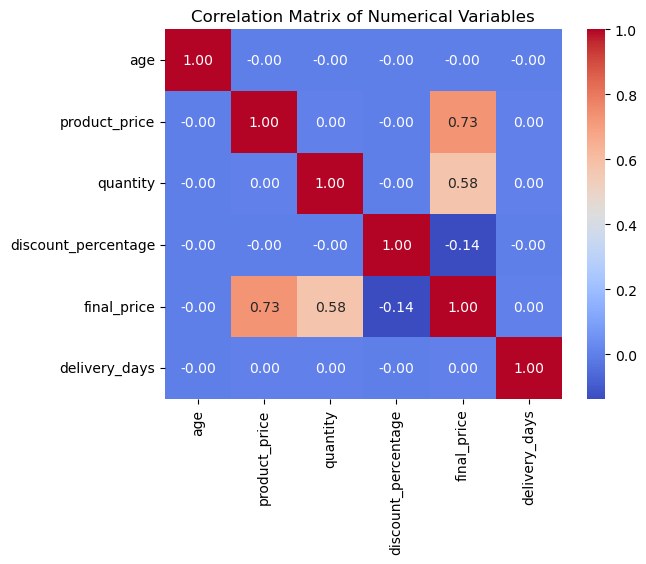

In [124]:
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Matrix of Numerical Variables')
plt.show()

###Bivariate Analysis is Numerical vs Categorical.

In [125]:
#Customer Segment vs Average Final Price

In [126]:
df.groupby('customer_segment')['final_price'].mean().sort_values(ascending=False)

customer_segment
Premium    64430.451339
Regular    64303.154748
New        63766.749294
Name: final_price, dtype: float64

In [127]:
#Premium customers have the highest average final price.
#Regular customers are extremely close behind.
#New customers have the lowest average final price.
#However, the difference between the three segments is quite small.

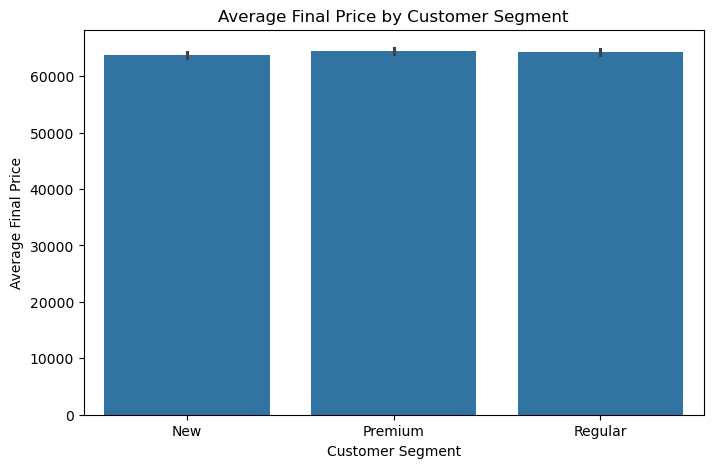

In [128]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='customer_segment',
    y='final_price',
    estimator='mean'
)

plt.title('Average Final Price by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Final Price')

plt.show()

In [129]:
#Product Category vs Return Rate

In [130]:
df.groupby('product_category')['return_status'].value_counts(normalize=True)

product_category  return_status
Beauty            No               0.852419
                  Yes              0.147581
Electronics       No               0.855273
                  Yes              0.144727
Fashion           No               0.849515
                  Yes              0.150485
Grocery           No               0.851314
                  Yes              0.148686
Health            No               0.851702
                  Yes              0.148298
Home & Kitchen    No               0.851140
                  Yes              0.148860
Name: proportion, dtype: float64

In [131]:
#Fashion has the highest return rate at approximately 15.05%.
#Electronics actually has the lowest return rate at approximately 14.47% in your dataset.
#The return rates are very similar across all categories, with only a small difference of about 0.58 percentage points between the highest and lowest.

In [132]:
df['return_status'].unique()

array(['No', 'Yes'], dtype=object)

In [133]:
df['returned'] = df['return_status'].map({
    'Yes': 1,
    'No': 0
})

return_rate = df.groupby('product_category')['returned'].mean() * 100

return_rate

product_category
Beauty            14.758069
Electronics       14.472732
Fashion           15.048456
Grocery           14.868611
Health            14.829754
Home & Kitchen    14.886040
Name: returned, dtype: float64

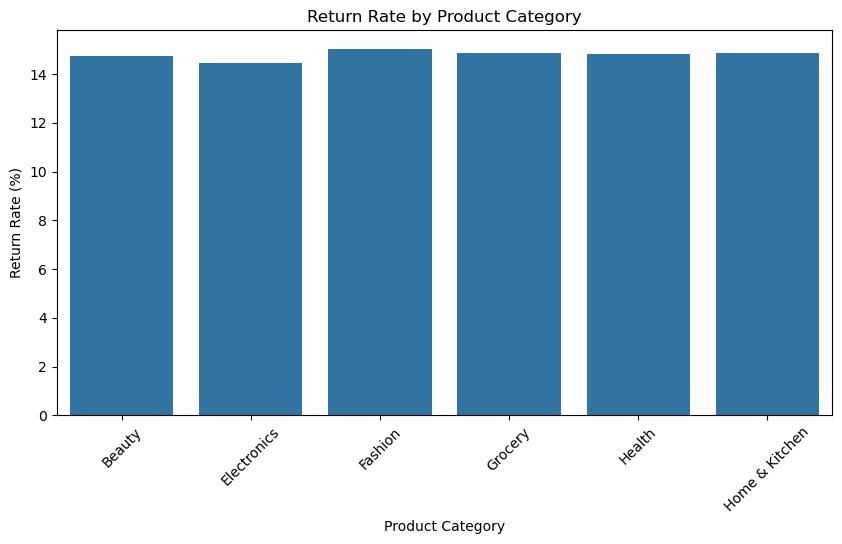

In [134]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=return_rate.index,
    y=return_rate.values
)

plt.title('Return Rate by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Return Rate (%)')

plt.xticks(rotation=45)
plt.show()

In [135]:
##Shipping Type vs Delivery Days 

In [136]:
df.groupby('shipping_type')['delivery_days'].mean().sort_values()

shipping_type
Express     5.497400
Standard    5.513682
Name: delivery_days, dtype: float64

In [137]:
#Express shipping has a slightly lower average delivery time than Standard shipping.
#However, the difference is extremely small, only about 0.016 days, so there is very little practical difference between the two shipping types in this dataset.

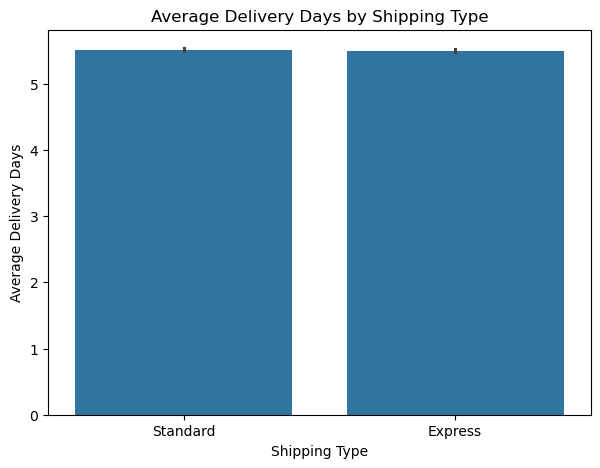

In [138]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x='shipping_type',
    y='delivery_days',
    estimator='mean'
)

plt.title('Average Delivery Days by Shipping Type')
plt.xlabel('Shipping Type')
plt.ylabel('Average Delivery Days')

plt.show()

In [139]:
df.select_dtypes(include='object').columns

Index(['gender', 'city', 'state', 'customer_segment', 'order_id', 'order_date',
       'product_category', 'product_subcategory', 'payment_method',
       'shipping_type', 'return_status'],
      dtype='object')

In [140]:
pd.crosstab(
    df['customer_segment'],
    df['return_status'],
    normalize='index'
) * 100

return_status,No,Yes
customer_segment,,
New,85.102126,14.897874
Premium,85.167868,14.832132
Regular,85.297203,14.702797


In [141]:
#New customers have the highest return rate at approximately 14.90%.
#Regular customers have the lowest return rate at approximately 14.70%.
#However, the difference between all three segments is very small, so customer segment does not appear to have a strong relationship with return status.

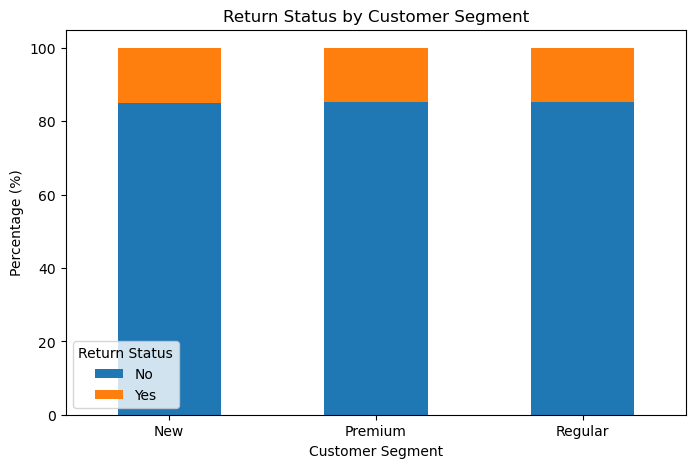

In [142]:
segment_return = pd.crosstab(
    df['customer_segment'],
    df['return_status'],
    normalize='index'
) * 100

segment_return.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Return Status by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)

plt.legend(title='Return Status')
plt.show()

In [143]:
##Product Category vs Shipping Type

In [144]:
#percentage of Express vs Standard shipping within each product category.

In [145]:
pd.crosstab(
    df['product_category'],
    df['shipping_type'],
    normalize='index'
) * 100

shipping_type,Express,Standard
product_category,,
Beauty,50.239205,49.760795
Electronics,50.168919,49.831081
Fashion,49.413110,50.586890
Grocery,49.752893,50.247107
Health,50.320323,49.679677
Home & Kitchen,50.148386,49.851614


In [146]:
#The distribution is almost perfectly balanced across every product category.
#Health has the highest Express shipping percentage at 50.32%.
#Fashion has the highest Standard shipping percentage at 50.59%.
#Overall, there appears to be no strong relationship between product category and shipping type in this dataset.

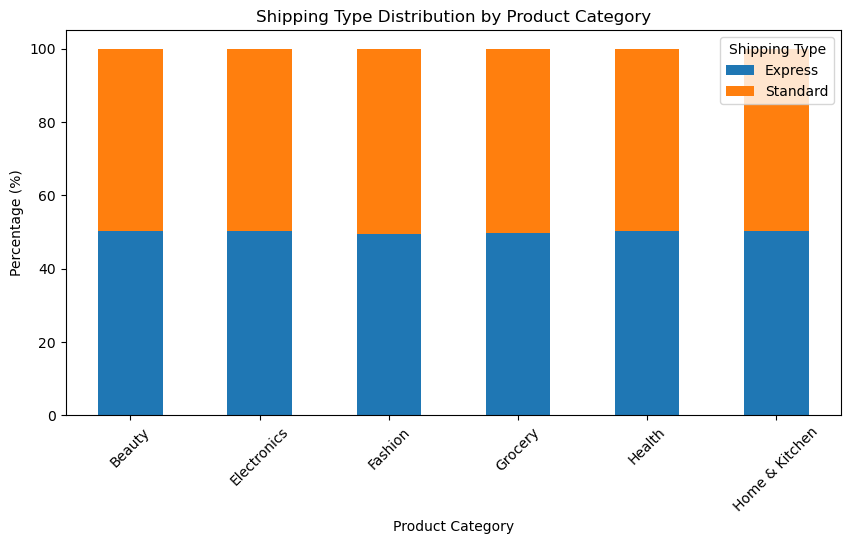

In [147]:
category_shipping = pd.crosstab(
    df['product_category'],
    df['shipping_type'],
    normalize='index'
) * 100

category_shipping.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.title('Shipping Type Distribution by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Percentage (%)')

plt.xticks(rotation=45)
plt.legend(title='Shipping Type')

plt.show()

In [148]:
##Multivariate Analysis

In [149]:
#the relationship between product category, discount percentage, and average final price.

In [150]:
df.groupby('product_category').agg(
    avg_discount=('discount_percentage', 'mean'),
    avg_final_price=('final_price', 'mean')
).sort_values('avg_final_price', ascending=False)

,avg_discount,avg_final_price
product_category,,
Home & Kitchen,15.042320,64840.420692
Electronics,14.944196,64329.670769
Grocery,15.093238,64101.808490
Beauty,15.021195,64030.551411
Fashion,14.966171,64002.188248
Health,14.992051,63686.691925


In [151]:
#Home & Kitchen has the highest average final price.
#Electronics is second, but does not have the highest revenue in your dataset.
#The average discount is almost identical across all categories, around 15%.
#Therefore, based on this analysis alone, there is no strong evidence that one particular discount level is driving higher final prices.

In [152]:
#visualize this multivariate relationship

In [153]:
#X-axis: Average Discount
#Y-axis: Average Final Price
#Each point represents a Product Category

In [154]:
category_analysis = df.groupby('product_category').agg(
    avg_discount=('discount_percentage', 'mean'),
    avg_final_price=('final_price', 'mean')
).reset_index()

category_analysis

,product_category,avg_discount,avg_final_price
0,Beauty,15.021195,64030.551411
1,Electronics,14.944196,64329.670769
2,Fashion,14.966171,64002.188248
3,Grocery,15.093238,64101.808490
4,Health,14.992051,63686.691925
5,Home & Kitchen,15.042320,64840.420692


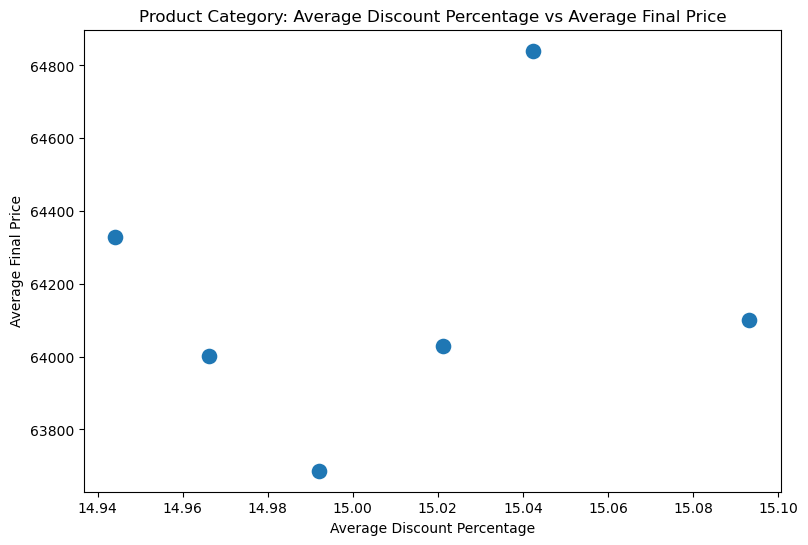

In [155]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=category_analysis,
    x='avg_discount',
    y='avg_final_price',
    s=150
)

plt.title('Product Category: Average Discount Percentage vs Average Final Price')
plt.xlabel('Average Discount Percentage')
plt.ylabel('Average Final Price')

plt.show()

In [156]:
segment_category_price = df.pivot_table(
    index='customer_segment',
    columns='product_category',
    values='final_price',
    aggfunc='mean'
)

segment_category_price

product_category,Beauty,Electronics,Fashion,Grocery,Health,Home & Kitchen
customer_segment,,,,,,
New,63716.730620,63655.898955,63547.017767,63678.493803,63347.191927,64651.966718
Premium,63709.710615,65030.334264,64908.736715,65062.240149,63755.140147,64156.947554
Regular,64669.346444,64313.753148,63577.055995,63572.438078,63952.691974,65712.033493


In [157]:
#A few observations
#Regular customers have the highest average final price in:
#-Beauty: ₹64,669
#-Health: ₹63,953
#-Home & Kitchen: ₹65,712 

#Premium customers have the highest average final price in:
#-Electronics: ₹65,030
#-Fashion: ₹64,909
#-Grocery: ₹65,062

#The highest combination overall is:

#Regular × Home & Kitchen = ₹65,712

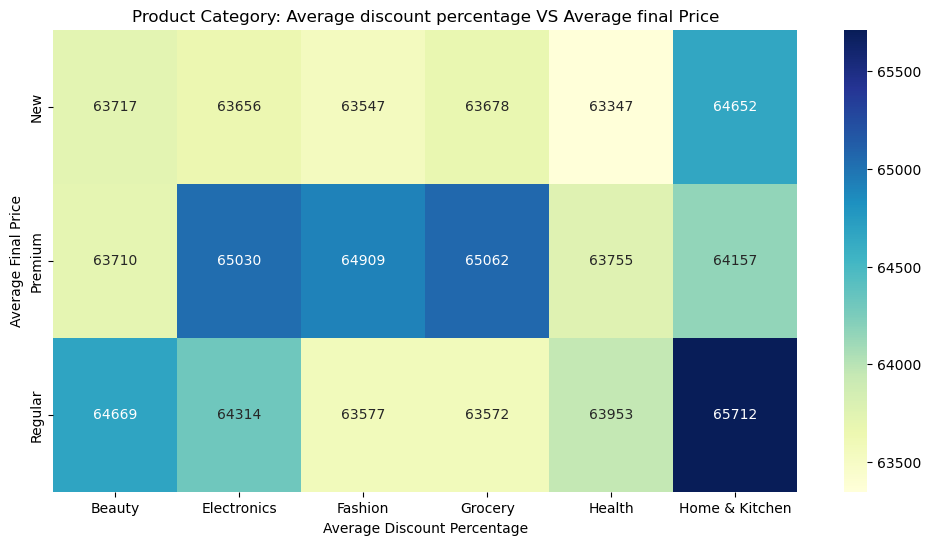

In [158]:
plt.figure(figsize=(12,6))

sns.heatmap(
    segment_category_price,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)
plt.title('Product Category: Average discount percentage VS Average final Price')
plt.xlabel('Average Discount Percentage')
plt.ylabel('Average Final Price')
    
plt.show()

In [159]:
#Shipping Type × Product Category × Delivery Days

In [160]:
#check the average delivery days for each combination of shipping type and product category.

In [161]:
shipping_category_delivery = df.pivot_table(
    index='shipping_type',
    columns='product_category',
    values='delivery_days',
    aggfunc='mean'
)
shipping_category_delivery

product_category,Beauty,Electronics,Fashion,Grocery,Health,Home & Kitchen
shipping_type,,,,,,
Express,5.542068,5.478716,5.528932,5.463477,5.497819,5.474021
Standard,5.503468,5.482446,5.502856,5.529447,5.528478,5.534826


In [162]:
#Key observations:
#Express shipping is faster for:
#-Electronics: 5.48 days
#-Grocery: 5.46 days
#-Health: 5.50 days
#-Home & Kitchen: 5.47 days

#Standard shipping is slightly faster for:
#-Beauty: 5.50 days
#-Beauty: 5.50 days

#The delivery times are very similar across all product categories and shipping types, ranging roughly from 5.46 to 5.54 days

#The differences are quite small, suggesting that in this dataset, shipping type and product category do not have a strong impact on delivery days

In [163]:
#heatmap

In [164]:
shipping_category_delivery

product_category,Beauty,Electronics,Fashion,Grocery,Health,Home & Kitchen
shipping_type,,,,,,
Express,5.542068,5.478716,5.528932,5.463477,5.497819,5.474021
Standard,5.503468,5.482446,5.502856,5.529447,5.528478,5.534826


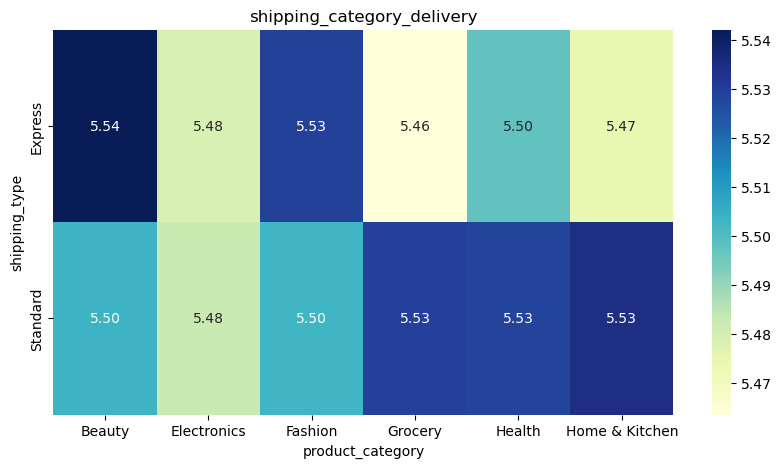

In [165]:
plt.figure(figsize=(10,5))
sns.heatmap(
    shipping_category_delivery,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu'
)
plt.title('shipping_category_delivery')
plt.xlabel('product_category')
plt.ylabel('shipping_type')
plt.show()

In [166]:
df['age'].dtype

dtype('int64')

In [167]:
df['age'].describe()

count    100000.000000
mean         41.561830
std          13.852439
min          18.000000
25%          30.000000
50%          42.000000
75%          54.000000
max          65.000000
Name: age, dtype: float64

In [168]:
df['age'].value_counts().sort_index()

age
18    2028
19    2104
20    2032
21    2042
22    2064
23    2104
24    2144
25    2081
26    2167
27    1996
28    2074
29    2116
30    2018
31    2017
32    2067
33    2051
34    2197
35    2015
36    2088
37    1973
38    2108
39    2120
40    2098
41    2097
42    2077
43    2020
44    2102
45    2132
46    2152
47    2049
48    2107
49    2112
50    2057
51    2116
52    2049
53    2095
54    2126
55    2045
56    2134
57    2051
58    2129
59    2033
60    2057
61    2155
62    2114
63    2056
64    2132
65    2099
Name: count, dtype: int64

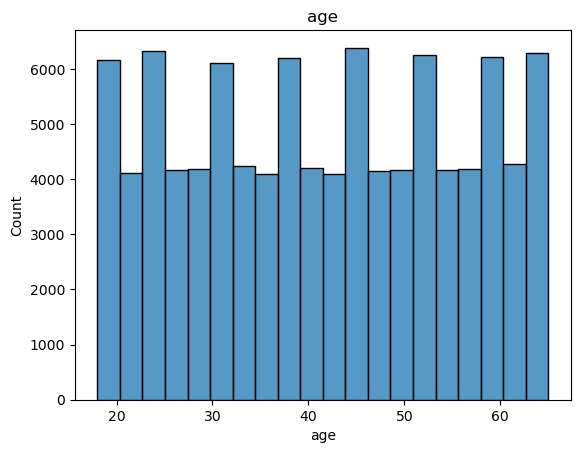

In [169]:
sns.histplot(df['age'],bins=20)
plt.title('age')
plt.show()

In [170]:
df[['customer_segment', 'age', 'final_price']].dtypes

customer_segment     object
age                   int64
final_price         float64
dtype: object

In [171]:
#Find average final price by customer segment.

In [172]:
df.groupby('customer_segment')['final_price'].mean()

customer_segment
New        63766.749294
Premium    64430.451339
Regular    64303.154748
Name: final_price, dtype: float64

In [173]:
#Each age from 18 to 65 has approximately:
#Lowest count: around 1,973 (age 37)
#Highest count: around 2,197 (age 34)
#Most ages: approximately 2,000–2,150 observations
##age data appears to be fairly evenly distributed across the entire age range. There are no obvious missing age ranges or major clusters.

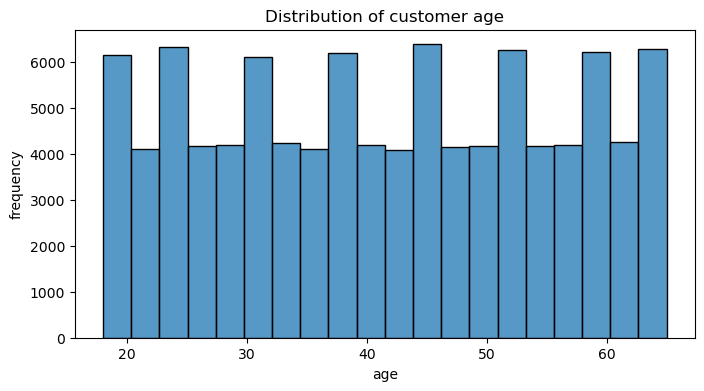

In [174]:
plt.figure(figsize=(8,4))
sns.histplot(
    data=df,
    x='age',
    bins=20
)
plt.title('Distribution of customer age')
plt.xlabel('age')
plt.ylabel('frequency')

plt.show()

In [175]:
segment_age_spending = df.groupby(
    ['customer_segment','age']
)['final_price'].mean().reset_index()

In [176]:
segment_age_spending

,customer_segment,age,final_price
0,New,18,62932.961697
1,New,19,67704.149448
2,New,20,63139.139323
3,New,21,65704.957447
4,New,22,61803.469074
...,...,...,...
139,Regular,61,68413.301676
140,Regular,62,61636.815676
141,Regular,63,62133.647351
142,Regular,64,67333.531583


In [177]:
segment_age_spending.head()

,customer_segment,age,final_price
0,New,18,62932.961697
1,New,19,67704.149448
2,New,20,63139.139323
3,New,21,65704.957447
4,New,22,61803.469074


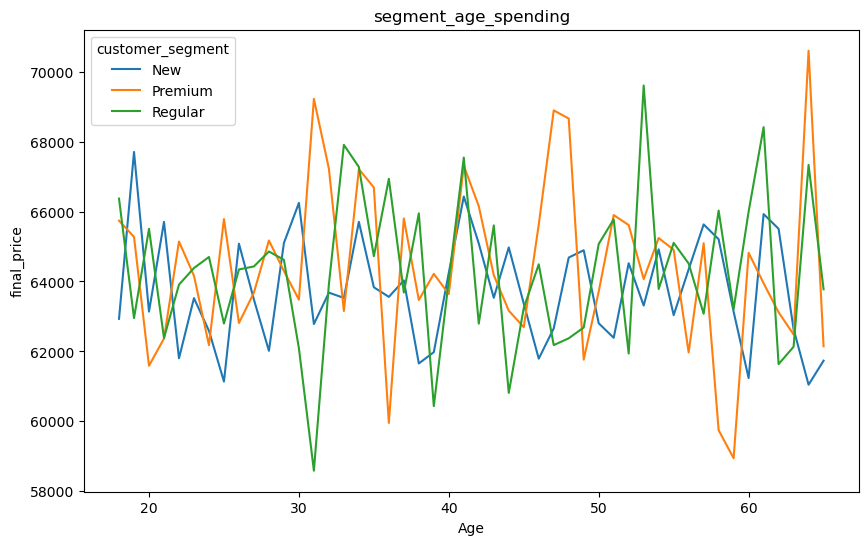

In [178]:
plt.figure(figsize=(10,6))

sns.lineplot(
    data=segment_age_spending,
    x='age',
y='final_price',
hue='customer_segment'
)

plt.title('segment_age_spending')
plt.xlabel('Age')
plt.ylabel('final_price')

plt.show()

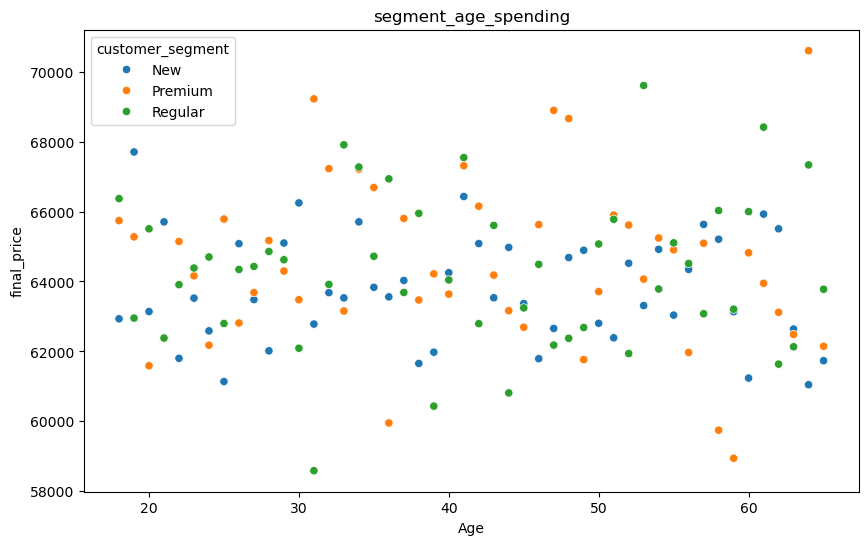

In [179]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=segment_age_spending,
    x='age',
y='final_price',
hue='customer_segment'
)

plt.title('segment_age_spending')
plt.xlabel('Age')
plt.ylabel('final_price')

plt.show()

In [180]:
#Age does not appear to have a strong relationship with average final price, and the spending patterns across New, Premium, and Regular customer segments largely overlap.

In [181]:
##create the 3 variable analysis

In [182]:
#Delivery Days × Shipping Type × Return Status

In [183]:
delivery_shipping_return= df.groupby(
    ['return_status', 'shipping_type'])['delivery_days'].mean().reset_index()

delivery_shipping_return

,return_status,shipping_type,delivery_days
0,No,Express,5.495076
1,No,Standard,5.514729
2,Yes,Express,5.510661
3,Yes,Standard,5.507615


In [184]:
#For orders not returned, Express is slightly faster: 5.495 vs 5.515 days
#For returned orders, Standard is very slightly faster: 5.508 vs 5.511 days

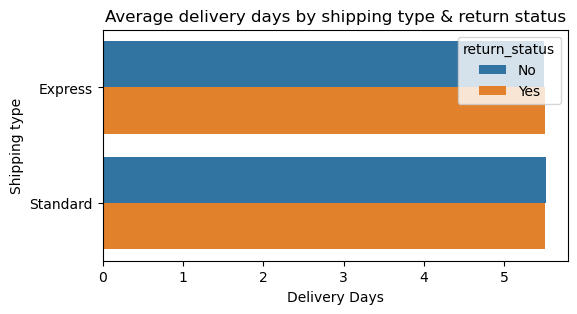

In [185]:
plt.figure(figsize=(6,3))

sns.barplot(
    data=delivery_shipping_return,
    x='delivery_days',
    y='shipping_type',
    hue='return_status'
)

plt.title('Average delivery days by shipping type & return status')
plt.xlabel('Delivery Days')
plt.ylabel('Shipping type')

plt.show()

In [186]:
#The average delivery time is almost identical across the four combinations:
#-No return + Express: 5.495 days
#No return + Standard: 5.515 days
#Return + Express: 5.511 days
#Return + Standard: 5.508 days

In [187]:
#Delivery days show very little variation across shipping types and return statuses, suggesting that neither shipping type nor return status has a significant impact on average delivery time in this dataset.

In [188]:
##Skewness & Kurtosis
numeric_cols=df.select_dtypes(include='number').columns

numeric_cols

Index(['age', 'product_price', 'quantity', 'discount_percentage',
       'final_price', 'delivery_days', 'returned'],
      dtype='object')

In [189]:
numeric_cols = ['age', 'product_price', 'quantity', 'discount_percentage',
       'final_price', 'delivery_days', 'returned']

skewness = df[numeric_cols].skew()
kurtosis = df[numeric_cols].kurtosis()

stats = pd.DataFrame({
    'Skewness': skewness,
'kurtosis': kurtosis})

stats

,Skewness,kurtosis
age,-0.004988,-1.201172
product_price,0.003249,-1.195106
quantity,-0.003067,-1.364612
discount_percentage,-0.003597,-1.201628
final_price,0.934747,0.169047
delivery_days,0.002270,-1.221514
returned,1.981342,1.925755


In [190]:
#final_price has a skewness of 0.935.

#That means the distribution has a noticeable right tail, with some transactions having much higher final prices than the majority.

In [192]:
#actual product_price skewness is only 0.003, which is essentially symmetric.
#however product_price is positively skewed
#final_price kurtosis is:#
#This is slightly positive, meaning the distribution has somewhat heavier tails than a normal distribution, but it is not extremely high.
#Most of your other variables have negative kurtosis, around -1.2 to -1.36.
#this indicates relatively lighter/ flatter tails compared with a normal distribution.
#data says "high kurtosis" for final_price, but our actual value is only 0.169

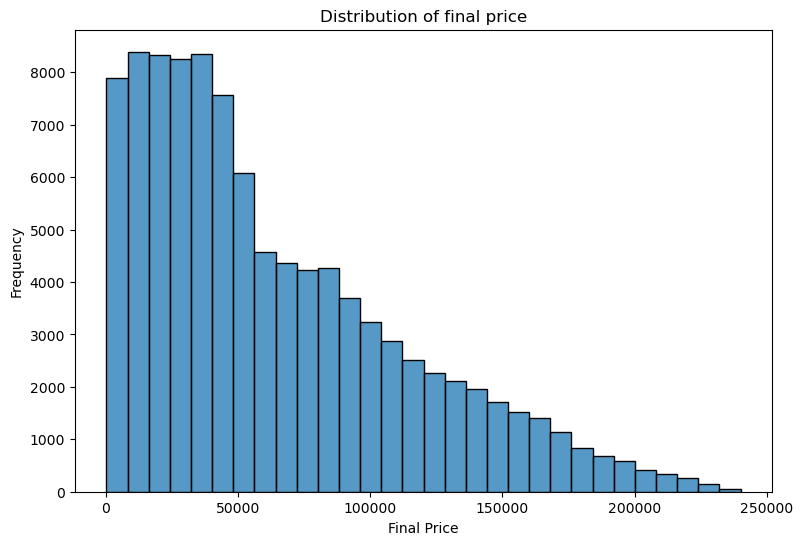

In [196]:
plt.figure(figsize=(9,6))

sns.histplot(
    data = df,
    x = 'final_price',
bins = 30,
)

plt.title('Distribution of final price')
plt.xlabel('Final Price')
plt.ylabel('Frequency')

plt.show()

In [198]:
#Skewness & Kurtosis conclusion

In [200]:
#final_price showed moderate positive skewness (0.935), indicating that most transactions were concentrated at lower-to-medium price levels, with a smaller number of high-value transactions creating a right tail. The kurtosis value (0.169) was slightly positive, indicating mildly heavier tails compared with a normal distribution.

In [201]:
###Finding1
#final_price skewness = 0.934747
#Final price showed moderate positive skewness (0.935), indicating that most transactions were concentrated at lower-to-medium price levels, while a smaller number of high-value transactions created a longer right tail.

In [202]:
#Finding2
#Revenue driven by high-value transactions
#A relatively small number of high-value transactions contributed substantially to the upper end of the final-price distribution, with high quantities contributing to some of these extreme values

In [203]:
#Finding3
#Outliers represent genuine premium purchases
#The detected final-price outliers appear to represent legitimate high-value transactions rather than automatically indicating erroneous data. These observations should therefore be investigated rather than removed without further business context.


In [204]:
###Key Statistical Findings

In [205]:
#1Final price was moderately right-skewed, with a skewness of 0.935, indicating a longer upper-price tail.

#2High-value transactions contributed to the upper end of the final-price distribution, with high quantities contributing to some extreme transactions.

#3Average discounts were approximately 15% across product categories, but our analysis did not establish that moderate discounts maximize spending.

#4Final-price outliers appear to represent potentially valid high-value transactions, so they should not be removed without additional business context.

#5Shipping type, delivery days, and return status showed very little difference in average delivery time, suggesting no meaningful relationship among these variables in this dataset.